<a href="https://colab.research.google.com/github/nageshnnazare/pytorch-expts/blob/main/2_autograd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

In [ ]:
x = torch.tensor([3.], requires_grad=True, dtype=torch.float64)
x

tensor([3.], dtype=torch.float64, requires_grad=True)

In [ ]:
y = x ** 2
y

tensor([9.], dtype=torch.float64, grad_fn=<PowBackward0>)

In [ ]:
y.backward()
x.grad

tensor([6.], dtype=torch.float64)

In [ ]:
!pip install torchviz --quiet

import math
from torchviz import make_dot

x = tensor([3.], requires_grad=True),
y = tensor([9.], grad_fn=<PowBackward0>),
z = tensor([5.0889], grad_fn=<AddBackward0>)
dy/dx = tensor([6.])
dz/dx = tensor([8.])


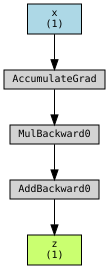

In [ ]:
x = torch.tensor([3.0], requires_grad=True)
y = x ** 2
z = 2 * x + math.cos(y)

print(f"x = {x},\ny = {y},\nz = {z}")
y.backward()
print(f"dy/dx = {x.grad}")

z.backward()
print(f"dz/dx = {x.grad}")
make_dot(z, params={"x":x, "y":y, "z":z})


# NN Example

In [ ]:
# Inputs
x = torch.tensor(6.7)
y = torch.tensor(0.0)

w = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

print(f"x = {x},\ny = {y},\nw = {w},\nb = {b}")

x = 6.699999809265137,
y = 0.0,
w = 1.0,
b = 0.0


In [ ]:
# Loss function
def binary_cross_entropy(y_hat, y):
  eps = 1e-8
  y_hat = torch.clamp(y_hat, eps, 1 - eps)
  return - (y * torch.log(y_hat) + (1 - y) * torch.log(1 - y_hat))

In [ ]:
# Forward pass
z = w * x + b
y_pred = torch.sigmoid(z)
loss = binary_cross_entropy(y_pred, y)

print(f"z = {z},\ny_pred = {y_pred},\nloss = {loss}")

z = 6.699999809265137,
y_pred = 0.998770534992218,
loss = 6.701176166534424


dw = 6.6917619705200195,
db = 0.9987704753875732


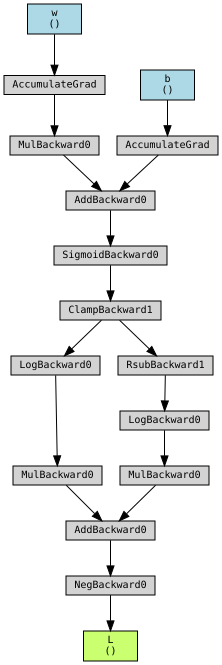

In [ ]:
# Back prop
loss.backward()

print(f"dw = {w.grad},\ndb = {b.grad}")
make_dot(loss, params={"w":w, "b":b, "L": loss})

# Tensor example

In [ ]:
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y = (x**2).mean()
print(f"x = {x},\ny = {y}")
y.backward()
print(f"dx = {x.grad}")

x = tensor([1., 2., 3.], requires_grad=True),
y = 4.666666507720947
dx = tensor([0.6667, 1.3333, 2.0000])


In [ ]:
# clear accumulating gradients
x.grad.zero_()

tensor([0., 0., 0.])

In [ ]:
# Disable grads
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
print(f"{x}")
x.requires_grad_(False)
print(f"{x}")

x = torch.tensor([4.0, 5.0, 6.0], requires_grad=True)
print(f"{x}")
y = x.detach()
print(f"{y}")

x = torch.tensor([7.0, 8.0, 9.0], requires_grad=True)
print(f"{x}")
with torch.no_grad():
  y = x + 2
  print(f"{x} {y}")

tensor([1., 2., 3.], requires_grad=True)
tensor([1., 2., 3.])
tensor([4., 5., 6.], requires_grad=True)
tensor([4., 5., 6.])
tensor([7., 8., 9.], requires_grad=True)
tensor([7., 8., 9.], requires_grad=True) tensor([ 9., 10., 11.])
